In [4]:
from ase.io import read
from PhononAnalyzer import PhononAnalyzer
import glob
try:
    import matplotlib.pyplot as plt
    _MPL_AVAILABLE = True
except ImportError:
    _MPL_AVAILABLE = False

from scipy.ndimage import gaussian_filter
import numpy as np

from matplotlib import rc

rc("text", usetex=True)
import matplotlib.pylab as pylab

params = {"legend.fontsize": "14",  "axes.labelsize": 20, "axes.titlesize": 20, "xtick.labelsize": 16, "ytick.labelsize": 16}
pylab.rcParams.update(params) 

In [ ]:
# load the trajectory
traj_200K_directory = "/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/200_K/"
traj_600K_directory = "/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/600_K/"

all_200K_traj_files = glob.glob(traj_200K_directory + "nve_md_*.traj")
all_600K_traj_files = glob.glob(traj_600K_directory + "nve_md_*.traj")
print(f"Found {len(all_200K_traj_files)} trajectory files for 200 K and {len(all_600K_traj_files)} trajectory files for 600 K.")

traj_200K =[]
for i in range(len(all_200K_traj_files)):
    print(f"Loading trajectory file {i+1}/{len(all_200K_traj_files)} for 200 K: {all_200K_traj_files[i]}")
    traj_name = traj_200K_directory + f"nve_md_{i+1}.traj"
    traj_200K += read(traj_name, index=":")
    if i == 0:
        traj_length = len(read(traj_name, index=":"))


traj_600K =[]
for i in range(len(all_600K_traj_files)):
    print(f"Loading trajectory file {i+1}/{len(all_600K_traj_files)} for 600 K: {all_600K_traj_files[i]}")
    traj_name = traj_600K_directory + f"nve_md_{i+1}.traj"
    traj_600K += read(traj_name, index=":")

# raise Exception("Stop here to avoid running the analysis again. Please comment out this line to run the analysis.")
# analyze the phonon properties

corr_length = int(traj_length/2)  # Use half the trajectory length for correlation to ensure good statistics
print("Correlation length (frames):", corr_length)

#corr_length = 1000

print("Analyzing phonon properties for 200 K trajectory with Li diffusion...")
phonon_analyzer_Li_200K = PhononAnalyzer(traj_200K, temperature=200, time_step=10.0, diffuse_atom="Li", zero_padding=1, corr_length=corr_length)
phonon_analyzer_Li_200K.compute_vacf(normalisation=False)
phonon_analyzer_Li_200K.compute_pdos()

print("Analyzing phonon properties for 600 K trajectory with Li diffusion...")
phonon_analyzer_Li_600K = PhononAnalyzer(traj_600K, temperature=600, time_step=10.0, diffuse_atom="Li", zero_padding=1, corr_length=corr_length)
phonon_analyzer_Li_600K.compute_vacf(normalisation=False)
phonon_analyzer_Li_600K.compute_pdos()

print("Analyzing phonon properties for 200 K trajectory for S ...")
phonon_analyzer_S_200K = PhononAnalyzer(traj_200K,temperature=200,time_step=10.0,zero_padding=1,diffuse_atom="S", corr_length=corr_length)
phonon_analyzer_S_200K.compute_vacf(normalisation=False)
phonon_analyzer_S_200K.compute_pdos()

print("Analyzing phonon properties for 200 K trajectory for P ...")
phonon_analyzer_P_200K = PhononAnalyzer(traj_200K,temperature=200,time_step=10.0,zero_padding=1,diffuse_atom="P", corr_length=corr_length)
phonon_analyzer_P_200K.compute_vacf(normalisation=False)
phonon_analyzer_P_200K.compute_pdos()   

print("Analyzing phonon properties for 200 K trajectory for Cl ...")
phonon_analyzer_Cl_200K = PhononAnalyzer(traj_200K,temperature=200,time_step=10.0,zero_padding=1,diffuse_atom="Cl", corr_length=corr_length)
phonon_analyzer_Cl_200K.compute_vacf(normalisation=False)
phonon_analyzer_Cl_200K.compute_pdos()

print("Analyzing phonon properties for 600 K trajectory for S ...")
phonon_analyzer_S_600K = PhononAnalyzer(traj_600K, temperature=600, time_step=10.0, zero_padding=1, diffuse_atom="S", corr_length=corr_length)
phonon_analyzer_S_600K.compute_vacf(normalisation=False)
phonon_analyzer_S_600K.compute_pdos()

print("Analyzing phonon properties for 600 K trajectory for P ...")
phonon_analyzer_P_600K = PhononAnalyzer(traj_600K, temperature=600, time_step=10.0, zero_padding=1, diffuse_atom="P", corr_length=corr_length)
phonon_analyzer_P_600K.compute_vacf(normalisation=False)
phonon_analyzer_P_600K.compute_pdos()   

print("Analyzing phonon properties for 600 K trajectory for Cl ...")
phonon_analyzer_Cl_600K = PhononAnalyzer(traj_600K, temperature=600, time_step=10.0, zero_padding=1, diffuse_atom="Cl", corr_length=corr_length)
phonon_analyzer_Cl_600K.compute_vacf(normalisation=False)
phonon_analyzer_Cl_600K.compute_pdos() 


Found 3 trajectory files for 200 K and 3 trajectory files for 600 K.
Loading trajectory file 1/3 for 200 K: /Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/200_K/nve_md_1.traj
Loading trajectory file 2/3 for 200 K: /Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/200_K/nve_md_2.traj
Loading trajectory file 3/3 for 200 K: /Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/FT_MACE_long_traj/200_K/nve_md_3.traj
Correlation length (frames): 12500


Exception: 

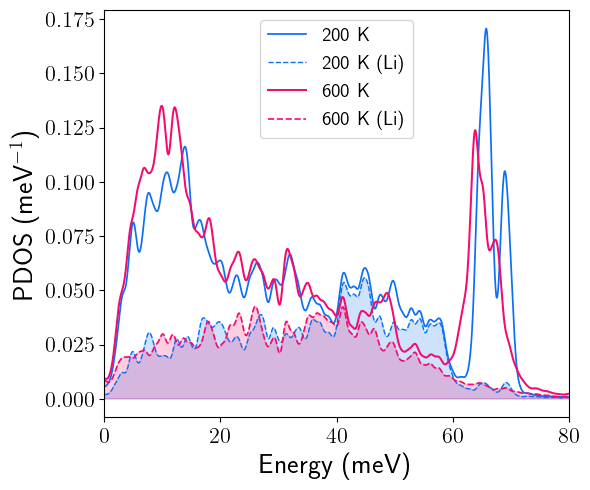

In [ ]:
import numpy as np
def _trapz(y: np.ndarray, x: np.ndarray) -> float:
    """Trapezoidal integration, compatible with all NumPy versions.

    Parameters:
        y: Integrand values, shape (N,).
        x: Abscissa values,  shape (N,).

    Returns:
        Scalar integral.
    """
    return float(np.sum((np.asarray(y[:-1]) + np.asarray(y[1:])) / 2.0 * np.diff(x)))

load_results = False

if load_results:
    import pickle
    Li_200K_pdos_result = pickle.load(
        open(
            "/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/phonon_dos_results/phonon_analyzer_Li_200K_results.pkl",
            "rb",
        )
    )
    Li_600K_pdos_result = pickle.load(
        open(
            "/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/phonon_dos_results/phonon_analyzer_Li_600K_results.pkl",
            "rb",
        )
    )
    S_200K_pdos_result = pickle.load(
        open(
            "/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/phonon_dos_results/phonon_analyzer_S_200K_results.pkl",
            "rb",
        )
    )
    P_200K_pdos_result = pickle.load(
        open(
            "/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/phonon_dos_results/phonon_analyzer_P_200K_results.pkl",
            "rb",
        )
    )
    Cl_200K_pdos_result = pickle.load(
        open(
            "/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/phonon_dos_results/phonon_analyzer_Cl_200K_results.pkl",
            "rb",
        )
    )
    S_600K_pdos_result = pickle.load(
        open(
            "/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/phonon_dos_results/phonon_analyzer_S_600K_results.pkl",
            "rb",
        )
    )
    P_600K_pdos_result = pickle.load(
        open(
            "/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/phonon_dos_results/phonon_analyzer_P_600K_results.pkl",
            "rb",
        )
    )
    Cl_600K_pdos_result = pickle.load(
        open(
            "/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/phonon_dos_results/phonon_analyzer_Cl_600K_results.pkl",
            "rb",
        )
    )
else:
    Li_200K_pdos_result = phonon_analyzer_Li_200K.pdos_result
    Li_600K_pdos_result = phonon_analyzer_Li_600K.pdos_result
    S_200K_pdos_result = phonon_analyzer_S_200K.pdos_result
    P_200K_pdos_result = phonon_analyzer_P_200K.pdos_result
    Cl_200K_pdos_result = phonon_analyzer_Cl_200K.pdos_result
    S_600K_pdos_result = phonon_analyzer_S_600K.pdos_result
    P_600K_pdos_result = phonon_analyzer_P_600K.pdos_result
    Cl_600K_pdos_result = phonon_analyzer_Cl_600K.pdos_result

_sigma = 15

Li_200_pdos = np.array(Li_200K_pdos_result.pdos)
Li_600_pdos = np.array(Li_600K_pdos_result.pdos)

others_200_pdos = np.array(S_200K_pdos_result.pdos) + np.array(P_200K_pdos_result.pdos) + np.array(Cl_200K_pdos_result.pdos)
others_600_pdos = np.array(S_600K_pdos_result.pdos) + np.array(P_600K_pdos_result.pdos) + np.array(Cl_600K_pdos_result.pdos)

total_200K_dos = Li_200_pdos + others_200_pdos
total_600K_dos = Li_600_pdos + others_600_pdos

norm_200K = _trapz(total_200K_dos, Li_200K_pdos_result.freq_THz)
norm_600K = _trapz(total_600K_dos, Li_600K_pdos_result.freq_THz)

Li_200_pdos_norm = np.array(Li_200_pdos) / norm_200K
Li_600_pdos_norm = np.array(Li_600_pdos) / norm_600K
total_200K_dos_norm = np.array(total_200K_dos) / norm_200K
total_600K_dos_norm = np.array(total_600K_dos) / norm_600K

filtered_dos_Li_200K = gaussian_filter(Li_200_pdos_norm, sigma=_sigma)
filtered_dos_Li_600K = gaussian_filter(Li_600_pdos_norm, sigma=_sigma)
filtered_dos_200K = gaussian_filter(total_200K_dos_norm, sigma=_sigma)
filtered_dos_600K = gaussian_filter(total_600K_dos_norm, sigma=_sigma)

plt.figure(figsize=(6, 5))
plt.plot(Li_200K_pdos_result.freq_THz*4.14, filtered_dos_200K, label="200 K", color="#0b70f4", linestyle="-", lw=1.25)
plt.plot(Li_200K_pdos_result.freq_THz * 4.14, filtered_dos_Li_200K, label="200 K (Li)", color="#0b70f4", linestyle="--", lw=1)
plt.plot(Li_600K_pdos_result.freq_THz*4.14, filtered_dos_600K, label="600 K", color="#f50a6e", linestyle="-",lw=1.45)
plt.plot(Li_600K_pdos_result.freq_THz * 4.14, filtered_dos_Li_600K, label="600 K (Li)", color="#f50a6e", linestyle="--", lw=1.2)
plt.fill_between(Li_200K_pdos_result.freq_THz*4.14, filtered_dos_Li_200K, color="#0b70f4", alpha=0.2)
plt.fill_between(Li_600K_pdos_result.freq_THz * 4.14, filtered_dos_Li_600K, color="#f50a6e", alpha=0.2)

plt.xlim([0,80])
# plt.ylim([0, 0.1])
plt.xlabel("Energy (meV)")
plt.ylabel("PDOS (meV$^{-1}$)")
plt.legend()
plt.tight_layout()
#plt.savefig("/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/total_pdos_vacf.pdf")
plt.show()

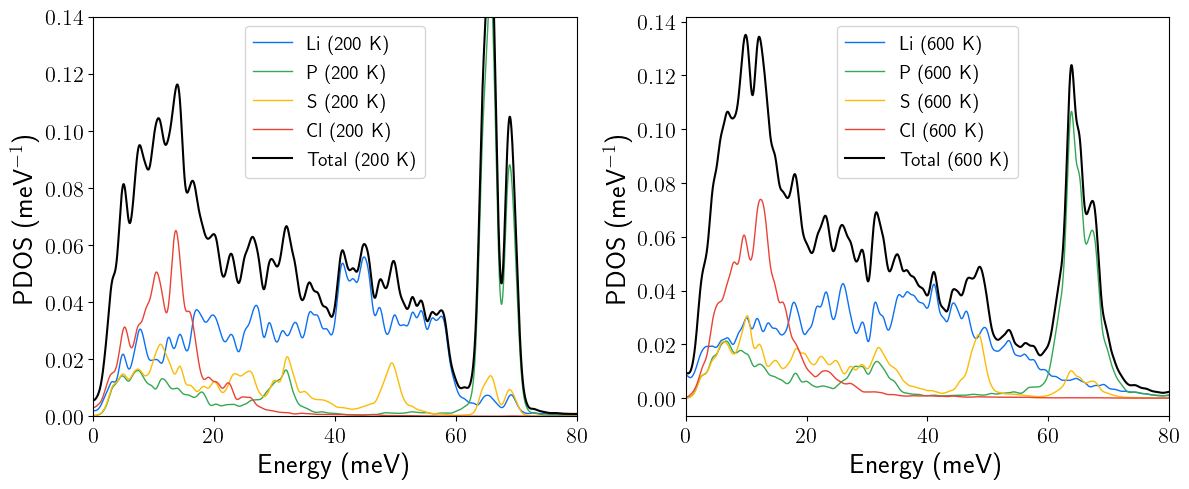

In [12]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(Li_200K_pdos_result.freq_THz * 4.14, filtered_dos_Li_200K, color="#0b70f4", linestyle="-", lw=1, label="Li (200 K)")

filtered_dos_P_200K = gaussian_filter(np.array(P_200K_pdos_result.pdos) / norm_200K, sigma=_sigma)
plt.plot(P_200K_pdos_result.freq_THz * 4.14, filtered_dos_P_200K, color="#34A853", linestyle="-", lw=1, label="P (200 K)")

filtered_dos_S_200K = gaussian_filter(np.array(S_200K_pdos_result.pdos) / norm_200K, sigma=_sigma)
plt.plot(S_200K_pdos_result.freq_THz * 4.14, filtered_dos_S_200K, color="#fbbc05", linestyle="-", lw=1, label="S (200 K)")

filtered_dos_Cl_200K = gaussian_filter(np.array(Cl_200K_pdos_result.pdos) / norm_200K, sigma=_sigma)
plt.plot(Cl_200K_pdos_result.freq_THz * 4.14, filtered_dos_Cl_200K, color="#EA4335", linestyle="-", lw=1, label="Cl (200 K)")

plt.plot(Li_200K_pdos_result.freq_THz * 4.14, filtered_dos_200K, color="k", linestyle="-", lw=1.5, label="Total (200 K)")

plt.xlim([0, 80])
plt.ylim([0, 0.14])
plt.xlabel("Energy (meV)")
plt.ylabel("PDOS (meV$^{-1}$)")
plt.legend()

plt.subplot(1,2,2)
plt.plot(Li_600K_pdos_result.freq_THz * 4.14, filtered_dos_Li_600K, color="#0b70f4", linestyle="-", lw=1, label="Li (600 K)")

filtered_dos_P_600K = gaussian_filter(np.array(P_600K_pdos_result.pdos) / norm_600K, sigma=_sigma)
plt.plot(P_600K_pdos_result.freq_THz * 4.14, filtered_dos_P_600K, color="#34A853", linestyle="-", lw=1, label="P (600 K)")

filtered_dos_S_600K = gaussian_filter(np.array(S_600K_pdos_result.pdos) / norm_600K, sigma=_sigma)
plt.plot(S_600K_pdos_result.freq_THz * 4.14, filtered_dos_S_600K, color="#fbbc05", linestyle="-", lw=1, label="S (600 K)")

filtered_dos_Cl_600K = gaussian_filter(np.array(Cl_600K_pdos_result.pdos) / norm_600K, sigma=_sigma)
plt.plot(Cl_600K_pdos_result.freq_THz * 4.14, filtered_dos_Cl_600K, color="#EA4335", linestyle="-", lw=1, label="Cl (600 K)")

plt.plot(Li_600K_pdos_result.freq_THz * 4.14, filtered_dos_600K, color="k", linestyle="-", lw=1.5, label="Total (600 K)")

plt.xlim([0, 80])
# plt.ylim([0, 0.14])
plt.xlabel("Energy (meV)")
plt.ylabel("PDOS (meV$^{-1}$)")
plt.legend()
plt.tight_layout()
plt.savefig("/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/partial_pdos_vacf.pdf")
plt.show()

Analyzing phonon properties for 200 K trajectory with Li diffusion...


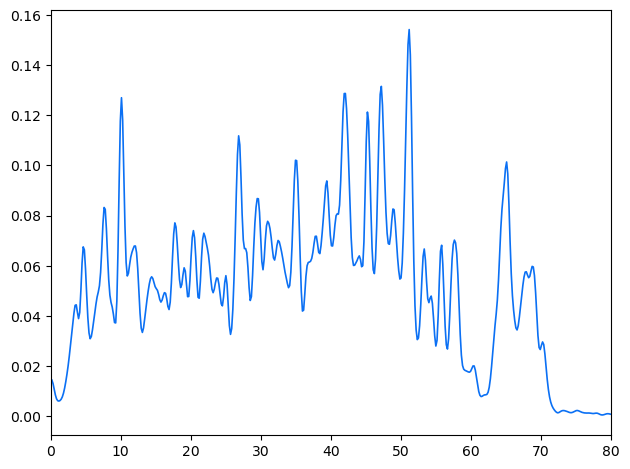

In [ ]:
corr_length = 2500

print("Analyzing phonon properties for 200 K trajectory with Li diffusion...")
phonon_analyzer_200K = PhononAnalyzer(traj_200K, temperature=200, time_step=10.0, zero_padding=1, corr_length=corr_length)
phonon_analyzer_200K.compute_vacf(normalisation=False)
phonon_analyzer_200K.compute_pdos()

pdos_200K = np.array(phonon_analyzer_200K.pdos_result.pdos)

_sigma = 2
filtered_dos_200K = gaussian_filter(pdos_200K/phonon_analyzer_200K.pdos_result.normalisation_constant, sigma=_sigma)
plt.plot(phonon_analyzer_200K.pdos_result.freq_THz*4.14, filtered_dos_200K, label="200K", color="#0b70f4", linestyle="-", lw=1.2)
plt.xlim([0, 80])
plt.tight_layout()
plt.show()

In [ ]:
import pickle
pickle.dump(phonon_analyzer_Li_200K.pdos_result, open("/Users/jackyang-macmini/scratch/LiPSCl-diffusion/nve_md/phonon_analyzer_Li_200K_results.pkl", "wb"))
pickle.dump(phonon_analyzer_Li_600K.pdos_result, open("/Users/jackyang-macmini/scratch/LiPSCl-diffusion/nve_md/phonon_analyzer_Li_600K_results.pkl", "wb"))
pickle.dump(phonon_analyzer_S_200K.pdos_result, open("/Users/jackyang-macmini/scratch/LiPSCl-diffusion/nve_md/phonon_analyzer_S_200K_results.pkl", "wb"))
pickle.dump(phonon_analyzer_P_200K.pdos_result, open("/Users/jackyang-macmini/scratch/LiPSCl-diffusion/nve_md/phonon_analyzer_P_200K_results.pkl", "wb"))
pickle.dump(phonon_analyzer_Cl_200K.pdos_result, open("/Users/jackyang-macmini/scratch/LiPSCl-diffusion/nve_md/phonon_analyzer_Cl_200K_results.pkl", "wb"))
pickle.dump(phonon_analyzer_S_600K.pdos_result, open("/Users/jackyang-macmini/scratch/LiPSCl-diffusion/nve_md/phonon_analyzer_S_600K_results.pkl", "wb"))
pickle.dump(phonon_analyzer_P_600K.pdos_result, open("/Users/jackyang-macmini/scratch/LiPSCl-diffusion/nve_md/phonon_analyzer_P_600K_results.pkl", "wb"))
pickle.dump(phonon_analyzer_Cl_600K.pdos_result, open("/Users/jackyang-macmini/scratch/LiPSCl-diffusion/nve_md/phonon_analyzer_Cl_600K_results.pkl", "wb"))

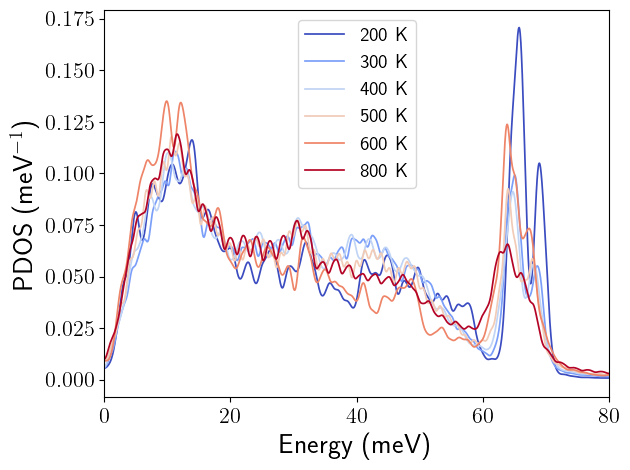

In [20]:
# analyse the temperature dependence of the phonon density of states

temperatures = [200, 300, 400, 500, 600, 800]

import numpy as np
def _trapz(y: np.ndarray, x: np.ndarray) -> float:
    """Trapezoidal integration, compatible with all NumPy versions.

    Parameters:
        y: Integrand values, shape (N,).
        x: Abscissa values,  shape (N,).

    Returns:
        Scalar integral.
    """
    return float(np.sum((np.asarray(y[:-1]) + np.asarray(y[1:])) / 2.0 * np.diff(x)))

colors = plt.cm.coolwarm(np.linspace(0, 1, len(temperatures)))


for temp in temperatures:
    Li_pdos_result = pickle.load(open("/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/phonon_dos_results/phonon_analyzer_{element}_{temp}K_results.pkl".format(element="Li", temp=temp), 'rb'))
    P_pdos_result = pickle.load(open("/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/phonon_dos_results/phonon_analyzer_{element}_{temp}K_results.pkl".format(element="P", temp=temp), 'rb'))
    S_pdos_result = pickle.load(open("/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/phonon_dos_results/phonon_analyzer_{element}_{temp}K_results.pkl".format(element="S", temp=temp), 'rb'))
    Cl_pdos_result = pickle.load(open("/Users/jackyang-macmini/OneDrive - UNSW/Documents/Projects/artificial_intelligence/LiPSCl-diffusion/nve_md/phonon_dos_results/phonon_analyzer_{element}_{temp}K_results.pkl".format(element="Cl", temp=temp), 'rb'))

    total_dos = np.array(Li_pdos_result.pdos) + np.array(P_pdos_result.pdos) + np.array(S_pdos_result.pdos) + np.array(Cl_pdos_result.pdos)
    norm = _trapz(total_dos, Li_pdos_result.freq_THz)
    total_dos_norm = total_dos / norm
    filtered_total_dos = gaussian_filter(total_dos_norm, sigma=15)

    # pick a color from the matplotlib colormap for each temperature
    plt.plot(Li_pdos_result.freq_THz*4.14, filtered_total_dos, label=f"{temp} K", color=colors[temperatures.index(temp)], linestyle="-", lw=1.25)

plt.xlim([0,80])
plt.xlabel("Energy (meV)")
plt.ylabel("PDOS (meV$^{-1}$)")
plt.legend()
plt.tight_layout()
plt.show()